In [1]:

# =====================================================
# 1. IMPORT LIBRARIES
# =====================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")


Libraries imported successfully


In [3]:
# Load dataset

df = pd.read_excel("sample_-_superstore.xls")
df

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9989,9990,CA-2014-110422,2014-01-21,2014-01-23,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.2480,3,0.20,4.1028
9990,9991,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.9600,2,0.00,15.6332
9991,9992,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.5760,2,0.20,19.3932
9992,9993,CA-2017-121258,2017-02-26,2017-03-03,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.6000,4,0.00,13.3200


In [4]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [6]:
df.shape

(9994, 21)

In [9]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [10]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [11]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:

# Create a copy
data = df.copy()

# Remove duplicate records
data.drop_duplicates(inplace=True)

# Convert date columns
data['Order Date'] = pd.to_datetime(data['Order Date'])
data['Ship Date'] = pd.to_datetime(data['Ship Date'])

# Handle missing values
for col in data.select_dtypes(include=np.number).columns:
    data[col] = data[col].fillna(data[col].median())

for col in data.select_dtypes(include='object').columns:
    data[col] = data[col].fillna(data[col].mode()[0])

# Extract date features
data['Order Year'] = data['Order Date'].dt.year
data['Order Month'] = data['Order Date'].dt.month
data['Order Day'] = data['Order Date'].dt.day

# Calculate shipping duration
data['Shipping Days'] = (
    data['Ship Date'] - data['Order Date']
).dt.days

# Remove unnecessary columns
data.drop(
    columns=[
        'Row ID', 'Order ID', 'Customer ID',
        'Customer Name', 'Country', 'Postal Code',
        'Product ID', 'Product Name',
        'Order Date', 'Ship Date'
    ],
    inplace=True
)

print("Data cleaning completed")
print(data.head())

print("\nRemaining missing values:")
print(data.isnull().sum().sum())

print("\nCleaned dataset shape:", data.shape)


Data cleaning completed
        Ship Mode    Segment             City       State Region  \
0    Second Class   Consumer        Henderson    Kentucky  South   
1    Second Class   Consumer        Henderson    Kentucky  South   
2    Second Class  Corporate      Los Angeles  California   West   
3  Standard Class   Consumer  Fort Lauderdale     Florida  South   
4  Standard Class   Consumer  Fort Lauderdale     Florida  South   

          Category Sub-Category     Sales  Quantity  Discount    Profit  \
0        Furniture    Bookcases  261.9600         2      0.00   41.9136   
1        Furniture       Chairs  731.9400         3      0.00  219.5820   
2  Office Supplies       Labels   14.6200         2      0.00    6.8714   
3        Furniture       Tables  957.5775         5      0.45 -383.0310   
4  Office Supplies      Storage   22.3680         2      0.20    2.5164   

   Order Year  Order Month  Order Day  Shipping Days  
0        2016           11          8              3  
1     

### EDA

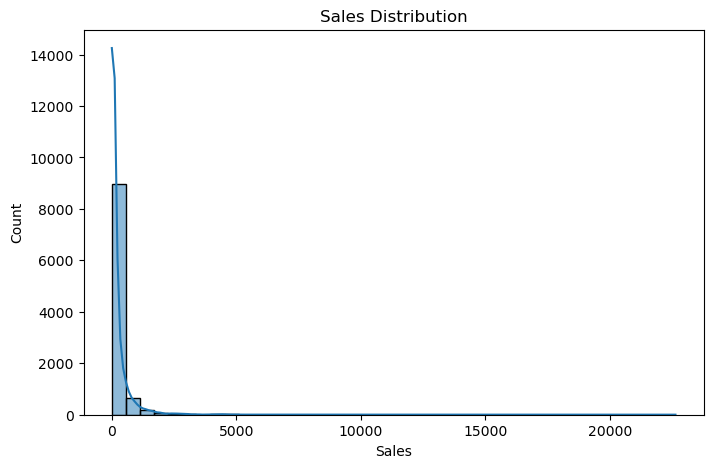

In [14]:
# Sales distribution
plt.figure(figsize=(8,5))
sns.histplot(data['Sales'], bins=40, kde=True)
plt.title("Sales Distribution")
plt.show()

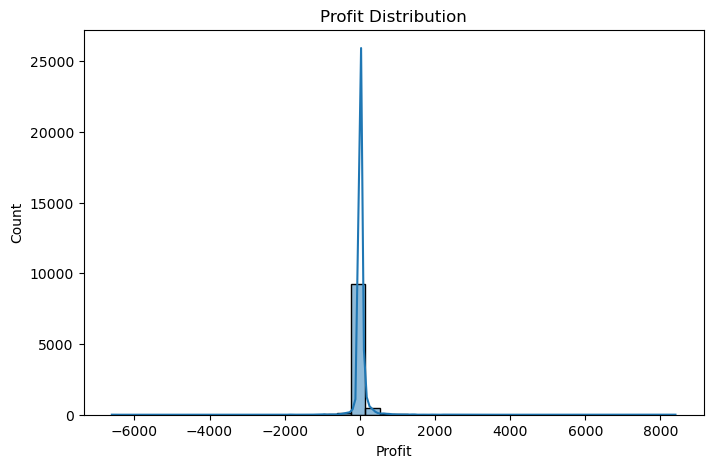

In [15]:
# Profit distribution
plt.figure(figsize=(8,5))
sns.histplot(data['Profit'], bins=40, kde=True)
plt.title("Profit Distribution")
plt.show()

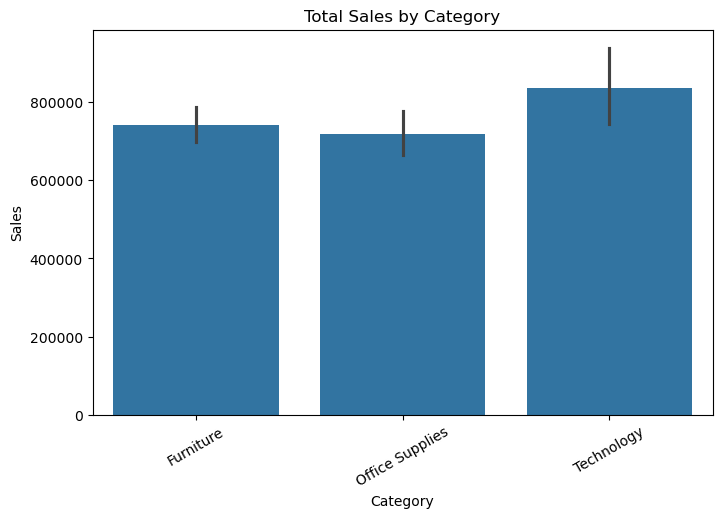

In [16]:
# Sales by Category
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Category', y='Sales', estimator='sum')
plt.title("Total Sales by Category")
plt.xticks(rotation=30)
plt.show()

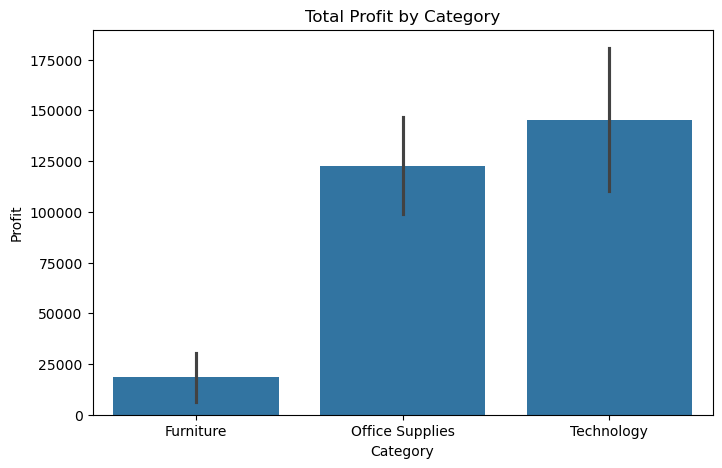

In [17]:
# Profit by Category
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Category', y='Profit', estimator='sum')
plt.title("Total Profit by Category")
plt.show()

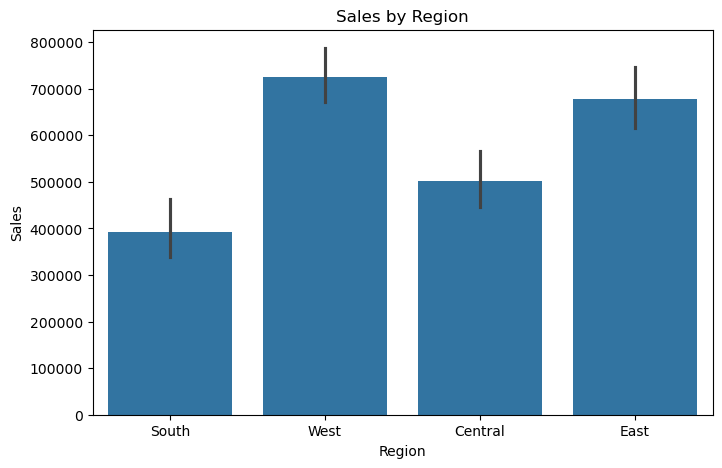

In [18]:
# Sales by Region
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Region', y='Sales', estimator='sum')
plt.title("Sales by Region")
plt.show()

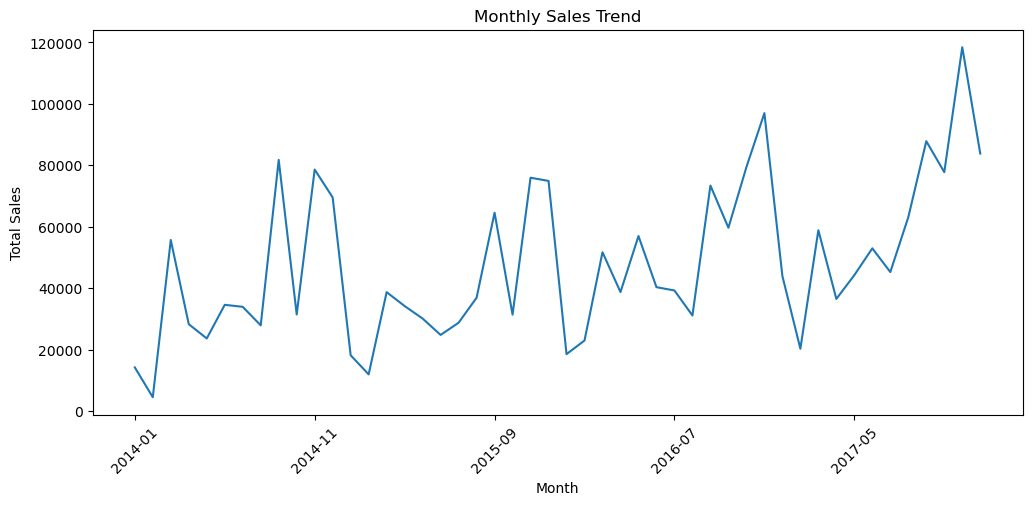

In [19]:
# Monthly Sales Trend
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

plt.figure(figsize=(12,5))
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot()
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

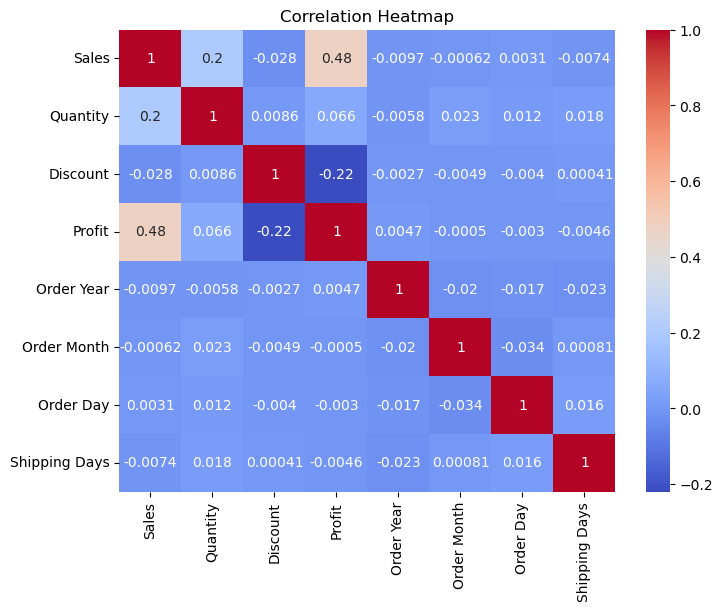

In [20]:
# Correlation heatmap
plt.figure(figsize=(8,6))
sns.heatmap(
    data.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Heatmap")
plt.show()

### Statistical Analysis and Hypothesis Testing

In [21]:
# 1. ANOVA Test: Sales across customer segments

consumer = df[df['Segment'] == 'Consumer']['Sales']
corporate = df[df['Segment'] == 'Corporate']['Sales']
home_office = df[df['Segment'] == 'Home Office']['Sales']

f_stat, p_value = stats.f_oneway(
    consumer, corporate, home_office
)

print("ANOVA Test")
print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Average sales differ across segments")
else:
    print("Fail to reject H0: No significant difference found")

ANOVA Test
F-statistic: 0.5951970006409847
P-value: 0.5514734705591805
Fail to reject H0: No significant difference found


In [22]:
# 2. Correlation Test: Discount and Profit

corr, p_value = stats.pearsonr(
    df['Discount'], df['Profit']
)

print("\nCorrelation Test")
print("Correlation:", corr)
print("P-value:", p_value)

if p_value < 0.05:
    print("Statistically significant correlation")
else:
    print("No statistically significant correlation")


Correlation Test
Correlation: -0.21948745637176847
P-value: 2.702294436198942e-109
Statistically significant correlation


In [23]:
# 3. T-test: Profit between high and low discount orders

high_discount = df[df['Discount'] >= 0.20]['Profit']
low_discount = df[df['Discount'] < 0.20]['Profit']

t_stat, p_value = stats.ttest_ind(
    high_discount,
    low_discount,
    equal_var=False
)

print("\nIndependent T-test")
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference in average profit")
else:
    print("No significant difference in average profit")


Independent T-test
T-statistic: -16.38707222497446
P-value: 1.5423257182410667e-59
Significant difference in average profit


### Machine Learning – Regression

In [24]:
# Prepare regression dataset

X = data.drop(columns=['Profit'])
y = data['Profit']

In [25]:
# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True)

In [26]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [27]:
# Initialize models
regression_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(
        random_state=42
    ),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

regression_results = []

In [28]:
# Train and evaluate models
for name, model in regression_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    regression_results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    print("\n", name)
    print("MAE:", mae)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


 Linear Regression
MAE: 72.53628566191861
MSE: 79101.27998899859
RMSE: 281.2494977577713
R2 Score: -0.631454569695808

 Decision Tree
MAE: 35.3173655827914
MSE: 87812.99410679878
RMSE: 296.3325734825633
R2 Score: -0.8111326458198016

 Random Forest
MAE: 27.61981650825413
MSE: 52841.37875865626
RMSE: 229.8725271942175
R2 Score: -0.08984720420234193


In [29]:
# Compare models
regression_comparison = pd.DataFrame(regression_results)

print("\nRegression Model Comparison:")
print(regression_comparison)


Regression Model Comparison:
               Model        MAE           MSE        RMSE  R2 Score
0  Linear Regression  72.536286  79101.279989  281.249498 -0.631455
1      Decision Tree  35.317366  87812.994107  296.332573 -0.811133
2      Random Forest  27.619817  52841.378759  229.872527 -0.089847


In [30]:
# Select best model based on lowest RMSE
best_regression_name = regression_comparison.loc[
    regression_comparison['RMSE'].idxmin(), 'Model'
]

best_regression_model = regression_models[
    best_regression_name
]

print("\nBest Regression Model:", best_regression_name)


Best Regression Model: Random Forest


### Regression visualization

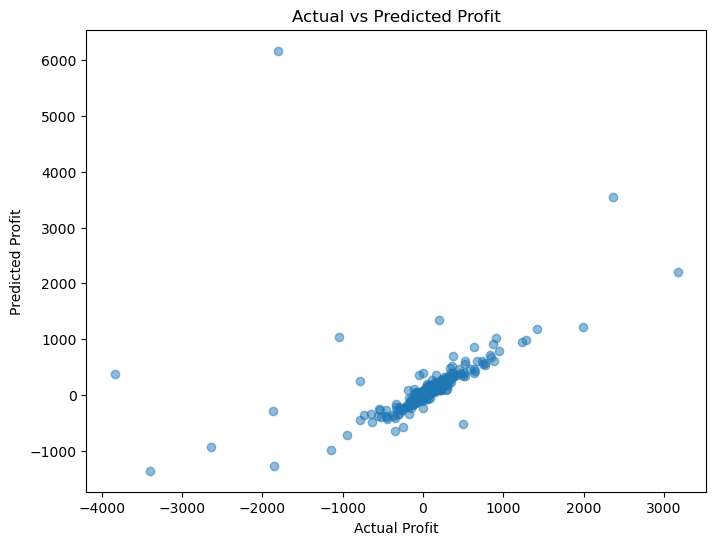

In [31]:
# Actual vs Predicted values

y_pred = best_regression_model.predict(X_test)

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.title("Actual vs Predicted Profit")

plt.show()

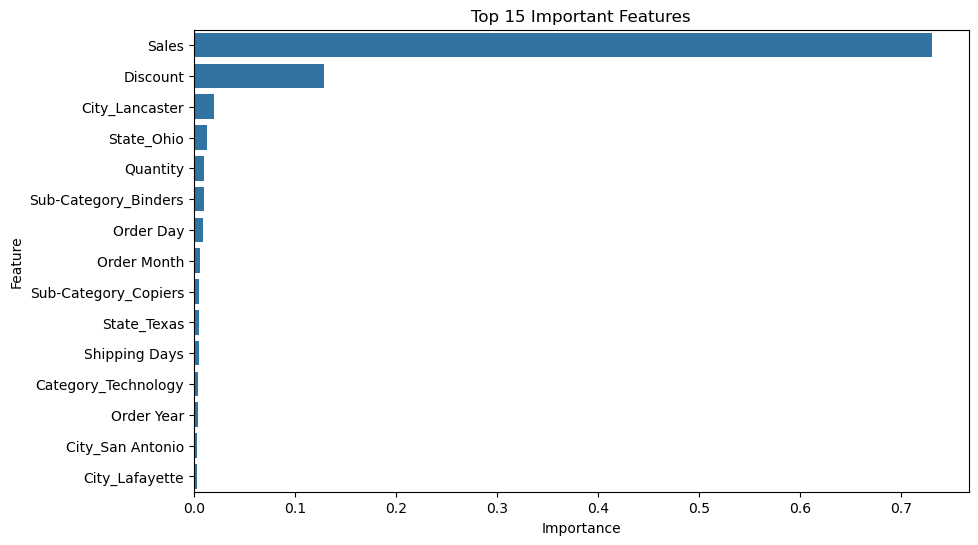

                  Feature  Importance
0                   Sales    0.730390
2                Discount    0.129158
252        City_Lancaster    0.019750
574            State_Ohio    0.012819
1                Quantity    0.009893
597  Sub-Category_Binders    0.009860
5               Order Day    0.009604
4             Order Month    0.006590
600  Sub-Category_Copiers    0.005486
582           State_Texas    0.005216
6           Shipping Days    0.004761
594   Category_Technology    0.004513
3              Order Year    0.004098
445      City_San Antonio    0.003619
244        City_Lafayette    0.003229


In [32]:
# Feature importance (Random Forest)

rf_model = regression_models['Random Forest']

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
).head(15)

plt.figure(figsize=(10,6))
sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

print(importance)

### Machine Learning – Classification

In [33]:
# Create classification target

classification_data = data.copy()

classification_data['Profitability'] = (
    classification_data['Profit'] > 0
).astype(int)

In [34]:
# Features and target
X_class = classification_data.drop(
    columns=['Profit', 'Profitability']
)

y_class = classification_data['Profitability']

In [35]:
# Encode categorical columns
X_class = pd.get_dummies(
    X_class,
    drop_first=True
)

In [36]:
# Train-test split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

In [37]:
# Initialize classification models
classification_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

classification_results = []

In [38]:
# Train and evaluate
for name, model in classification_models.items():

    model.fit(X_train_c, y_train_c)

    predictions = model.predict(X_test_c)

    accuracy = accuracy_score(y_test_c, predictions)
    precision = precision_score(
        y_test_c, predictions, zero_division=0
    )
    recall = recall_score(
        y_test_c, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test_c, predictions, zero_division=0
    )

    classification_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\n", name)
    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    print("\nClassification Report:")
    print(classification_report(
        y_test_c,
        predictions,
        zero_division=0
    ))


 Logistic Regression
Accuracy: 0.9369684842421211
Precision: 0.951397326852977
Recall: 0.9714640198511166
F1 Score: 0.9613259668508287

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.79      0.83       387
           1       0.95      0.97      0.96      1612

    accuracy                           0.94      1999
   macro avg       0.91      0.88      0.90      1999
weighted avg       0.94      0.94      0.94      1999


 Decision Tree
Accuracy: 0.9329664832416208
Precision: 0.9544895448954489
Recall: 0.9627791563275434
F1 Score: 0.958616429894997

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.81      0.82       387
           1       0.95      0.96      0.96      1612

    accuracy                           0.93      1999
   macro avg       0.90      0.89      0.89      1999
weighted avg       0.93      0.93      0.93      1999


 Random Forest
Accuracy: 0.9434

In [39]:
# Compare models
classification_comparison = pd.DataFrame(
    classification_results
)

print("\nClassification Model Comparison:")
print(classification_comparison)


Classification Model Comparison:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.936968   0.951397  0.971464  0.961326
1        Decision Tree  0.932966   0.954490  0.962779  0.958616
2        Random Forest  0.943472   0.941142  0.991935  0.965871


In [40]:
# Select best model based on F1 Score
best_classification_name = classification_comparison.loc[
    classification_comparison['F1 Score'].idxmax(),
    'Model'
]

best_classification_model = classification_models[
    best_classification_name
]

print("\nBest Classification Model:",
      best_classification_name)


Best Classification Model: Random Forest


### Confusion Matrix

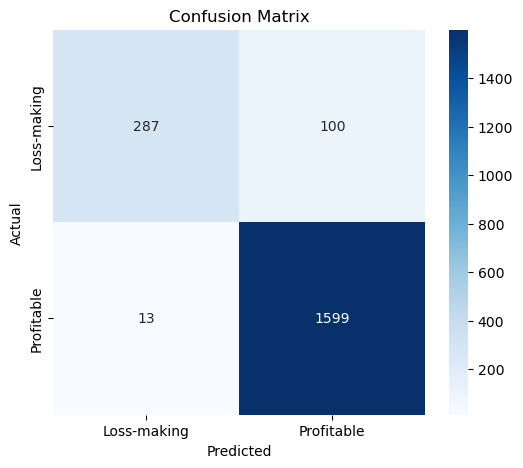

In [41]:
# Predict using best classification model

class_predictions = best_classification_model.predict(
    X_test_c
)

cm = confusion_matrix(
    y_test_c,
    class_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Loss-making', 'Profitable'],
    yticklabels=['Loss-making', 'Profitable']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


### Final Results and Save Outputs

In [42]:
# Save model comparison results

regression_comparison.to_csv(
    "regression_results.csv",
    index=False
)

classification_comparison.to_csv(
    "classification_results.csv",
    index=False
)

importance.to_csv(
    "feature_importance.csv",
    index=False
)

# Save predictions

prediction_output = pd.DataFrame({
    'Actual Profit': y_test.values,
    'Predicted Profit': y_pred
})

prediction_output.to_csv(
    "profit_predictions.csv",
    index=False
)

print("All analysis results saved successfully!")

print("\nPROJECT COMPLETED SUCCESSFULLY")


All analysis results saved successfully!

PROJECT COMPLETED SUCCESSFULLY
